In [12]:
# 1. Import packages
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# 2. Load dataset (Change only folder path)
dataset_path = './Object Detection/fashion mnist'

train = keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset='training',
    seed=123
)

test = keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset='validation',
    seed=123
)

# 3. Load VGG16 model
base = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# 4. Freeze VGG16
base.trainable = False

# 5. Create model
model = keras.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(train.class_names), activation='softmax')
])

# 6. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 7. Train model
history = model.fit(train, epochs=1, validation_data=test)

# 8. Evaluate model
model.evaluate(test)

# 9. Plot accuracy
print(history.history)

Found 1497 files belonging to 5 classes.
Using 1198 files for training.
Found 1497 files belonging to 5 classes.
Using 299 files for validation.
38/38 ━━━━━━━━━━━━━━━━━━━━ 1104s 29s/step - accuracy: 0.7521 - loss: 0.9415 - val_accuracy: 0.8729 - val_loss: 0.3549
10/10 ━━━━━━━━━━━━━━━━━━━━ 217s 22s/step - accuracy: 0.8729 - loss: 0.3549
{'accuracy': [0.7520868182182312], 'loss': [0.9414815306663513], 'val_accuracy': [0.8729097247123718], 'val_loss': [0.35485512018203735]}


1/1 ━━━━━━━━━━━━━━━━━━━━ 23s 23s/step


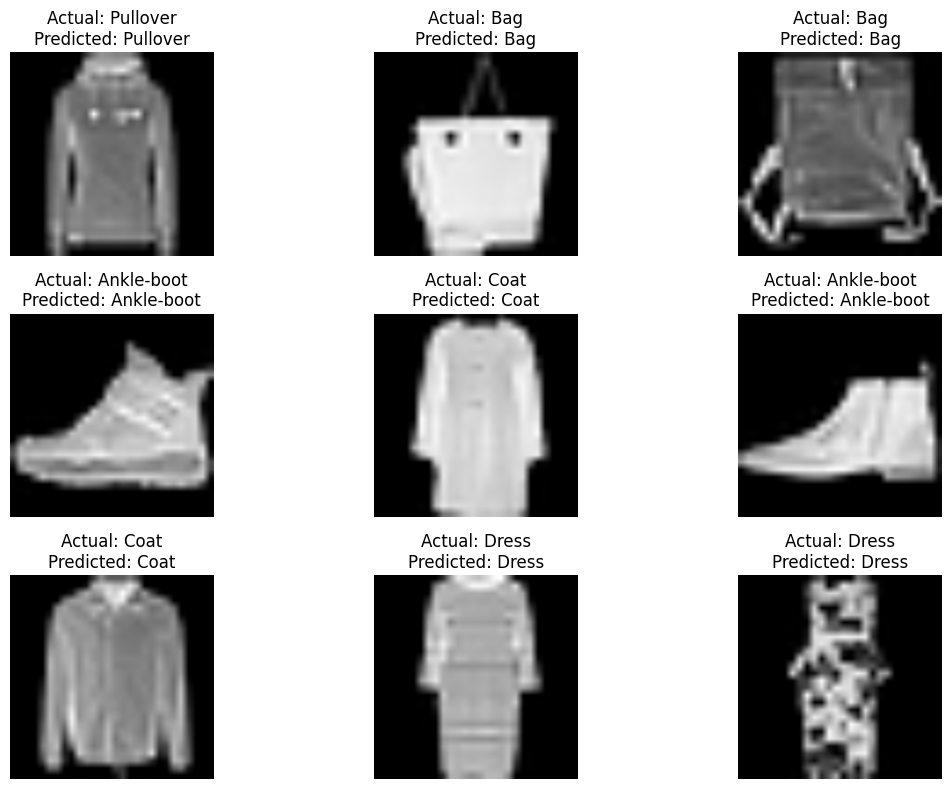

In [13]:
# 9. Display Actual and Predicted Images
class_names = train.class_names

plt.figure(figsize=(12, 8))

for images, labels in test.take(1):
    predictions = model.predict(images)

    for i in range(9):
        plt.subplot(3, 3, i+1)

        plt.imshow(images[i].numpy().astype('uint8'))

        actual = class_names[labels[i].numpy()]
        predicted = class_names[predictions[i].argmax()]

        plt.title('Actual: ' + actual + '\nPredicted: ' + predicted)
        plt.axis('off')

plt.tight_layout()
plt.show()